# Simple 2D Binary Classification (Linearly Separable) using Logistic Regression

## 1. Goal & Mathematical Formulation
Linear Regression predicts continuous target values $y \in \mathbb{R}$. **Logistic Regression** is used for **binary classification**, where the target variable $y \in \{0, 1\}$.

### Linear Combination in 2D Space
For a dataset with two features, $\mathbf{x} = [x_1, x_2]^T$, we calculate a linear combination using feature weights $w_1, w_2$ and a bias term $b$:

$$z = w_1 x_1 + w_2 x_2 + b$$

### The Sigmoid Function
Linear predictions ($z$) range from negative infinity to positive infinity $(-\infty, \infty)$. To transform $z$ into a valid probability bounded between $0$ and $1$, we pass it through the **Sigmoid (Logistic) function**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

For a sample $\mathbf{x}^{(i)}$, the predicted probability of belonging to Class 1 is:

$$\hat{y}^{(i)} = P(y^{(i)}=1 \mid \mathbf{x}^{(i)}) = \sigma(z^{(i)}) = \frac{1}{1 + e^{-(w_1 x_1^{(i)} + w_2 x_2^{(i)} + b)}}$$

### Decision Rule & Linear Boundary Equation
We classify predictions based on a $0.5$ probability threshold:
- If $\hat{y} \ge 0.5$, predict **Class 1** ($z \ge 0$).
- If $\hat{y} < 0.5$, predict **Class 0** ($z < 0$).

The **decision boundary** occurs precisely where $P(y=1) = 0.5$, corresponding to $z = 0$:

$$w_1 x_1 + w_2 x_2 + b = 0$$

Rearranging this into slope-intercept form ($x_2 = m x_1 + c$) yields the equation of a **separating line** in 2D space:

$$x_2 = -\frac{w_1}{w_2} x_1 - \frac{b}{w_2}$$

---

## 2. Cost Function: Binary Cross-Entropy (Log Loss)

Mean Squared Error (MSE) cannot be used for Logistic Regression because passing $z$ through the non-linear Sigmoid function results in a non-convex cost surface with multiple local minima.

Instead, we use **Binary Cross-Entropy (Log Loss)**:

$$J(w_1, w_2, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

- **When $y = 1$:** The loss simplifies to $-\log(\hat{y})$. As $\hat{y} \to 1$, loss $\to 0$. As $\hat{y} \to 0$, loss $\to \infty$.
- **When $y = 0$:** The loss simplifies to $-\log(1 - \hat{y})$. As $\hat{y} \to 0$, loss $\to 0$. As $\hat{y} \to 1$, loss $\to \infty$.

---

## 3. Optimization via Gradient Descent

Using the chain rule, the partial derivatives of the cost function $J$ with respect to the parameters are:

$$\frac{\partial J}{\partial w_1} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) x_1^{(i)}$$

$$\frac{\partial J}{\partial w_2} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) x_2^{(i)}$$

$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$

Vectorized for $\mathbf{w} = [w_1, w_2]^T$:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} \mathbf{X}^T (\mathbf{\hat{Y}} - \mathbf{Y})$$

### Parameter Update Rule:
$$\mathbf{w} := \mathbf{w} - \alpha \frac{\partial J}{\partial \mathbf{w}}$$
$$b := b - \alpha \frac{\partial J}{\partial b}$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

class MySimpleLogisticRegression:
    def __init__(self, learning_rate=0.1, epochs=2000):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        # Clip z to prevent numerical overflow in exp(-z)
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias = 0.0

        for epoch in range(self.epochs):
            # 1. Forward Pass
            linear_model = np.dot(X, self.weights) + self.bias
            y_pred_prob = self._sigmoid(linear_model)

            # 2. Compute Binary Cross-Entropy Cost
            eps = 1e-15  # Prevent log(0)
            y_pred_clipped = np.clip(y_pred_prob, eps, 1 - eps)
            cost = - (1 / m) * np.sum(
                y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped)
            )
            self.cost_history.append(cost)

            # 3. Compute Gradients
            dw = (1 / m) * np.dot(X.T, (y_pred_prob - y))
            db = (1 / m) * np.sum(y_pred_prob - y)

            # 4. Update Parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            if epoch % (self.epochs//10) == 0 or epoch == self.epochs - 1:
                print(f"  ➜ Epoch {epoch:4d} | Log Loss: {cost:.6f}")

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [3]:
# --- Usage Section ---

# Data Setup  (Synthetic Data for demonstration)

np.random.seed(42)

# 1. Set Known Ground-Truth Parameters
true_w = np.array([2.0, -1.2])
true_b = 0.5

print("=" * 60)
print(" GROUND TRUTH PARAMETERS")
print("=" * 60)
print(f" True w1 : {true_w[0]}")
print(f" True w2 : {true_w[1]}")
print(f" True b  : {true_b}")

# 2. Generate 2D Features
n_samples = 300
X = np.random.randn(n_samples, 2)

# 3. Compute Labels y using Ground Truth
z_true = np.dot(X, true_w) + true_b
probs_true = 1.0 / (1.0 + np.exp(-z_true))
y = (probs_true >= 0.5).astype(int)

# 4. Train Both Models
print("\nTraining Custom Gradient Descent Model...")
scratch_model = MySimpleLogisticRegression(learning_rate=0.1, epochs=2000)
scratch_model.fit(X, y)

print("\nTraining Scikit-Learn Logistic Regression...")
sk_model = LogisticRegression(penalty=None, solver='lbfgs')
sk_model.fit(X, y);  # Semicolon prevents HTML dump

 GROUND TRUTH PARAMETERS
 True w1 : 2.0
 True w2 : -1.2
 True b  : 0.5

Training Custom Gradient Descent Model...
  ➜ Epoch    0 | Log Loss: 0.693147
  ➜ Epoch  200 | Log Loss: 0.213888
  ➜ Epoch  400 | Log Loss: 0.162636
  ➜ Epoch  600 | Log Loss: 0.139066
  ➜ Epoch  800 | Log Loss: 0.124691
  ➜ Epoch 1000 | Log Loss: 0.114709
  ➜ Epoch 1200 | Log Loss: 0.107232
  ➜ Epoch 1400 | Log Loss: 0.101347
  ➜ Epoch 1600 | Log Loss: 0.096550
  ➜ Epoch 1800 | Log Loss: 0.092535
  ➜ Epoch 1999 | Log Loss: 0.089124

Training Scikit-Learn Logistic Regression...


In [5]:
# Compare Learned Parameters against Ground Truth
params_df = pd.DataFrame({
    "Parameter": ["w1 (x1 weight)", "w2 (x2 weight)", "Bias (b)"],
    "Ground Truth": [true_w[0], true_w[1], true_b],
    "Custom GD Model": [scratch_model.weights[0], scratch_model.weights[1], scratch_model.bias],
    "Scikit-Learn Model": [sk_model.coef_[0][0], sk_model.coef_[0][1], sk_model.intercept_[0]]
})

print("=" * 60)
print(" LEARNED PARAMETERS COMPARISON")
print("=" * 60)
print(params_df.to_string(index=False))

# Accuracy Comparison
acc_scratch = accuracy_score(y, scratch_model.predict(X))
acc_sk = accuracy_score(y, sk_model.predict(X))

print("\n" + "=" * 60)
print(" ACCURACY SCORE")
print("=" * 60)
print(f" Custom GD Model Accuracy : {acc_scratch * 100:.2f}%")
print(f" Scikit-Learn Accuracy   : {acc_sk * 100:.2f}%")

 LEARNED PARAMETERS COMPARISON
     Parameter  Ground Truth  Custom GD Model  Scikit-Learn Model
w1 (x1 weight)           2.0         5.801683          267.654918
w2 (x2 weight)          -1.2        -3.606410         -161.529848
      Bias (b)           0.5         1.327694           65.542695

 ACCURACY SCORE
 Custom GD Model Accuracy : 99.00%
 Scikit-Learn Accuracy   : 100.00%


## Why Do the Learned Weights Differ From Ground Truth?

When data is **perfectly linearly separable** without any overlapping points, Logistic Regression experiences **weight explosion**.

### 1. The Mathematics Behind Weight Explosion
The decision rule depends on the sign of $z = w_1 x_1 + w_2 x_2 + b$:
- If $z > 0 \implies \sigma(z) > 0.5 \implies \text{Class 1}$
- If $z < 0 \implies \sigma(z) < 0.5 \implies \text{Class 0}$

If a line correctly separates all points, scaling the weights by a constant $k > 1$ (e.g., $k \cdot \mathbf{w}$) keeps the **exact same line direction**, but drives $z \to \pm\infty$.

Since Sigmoid probabilities approach $1.0$ or $0.0$ as $z \to \pm\infty$, **Log Loss strictly decreases as weight magnitudes approach infinity**:

$$\lim_{k \to \infty} J(k \mathbf{w}, k b) = 0$$

Because the minimum loss occurs at $\infty$, Gradient Descent keeps pushing the weights higher with every epoch without ever reaching a finite optimal value.

---

### 2. Why Custom GD and Scikit-Learn Diverge
1. **Custom GD (Stopped Early):** Our custom model ran for 2,000 iterations with a fixed learning rate of $0.1$. It was still slowly climbing toward infinity when training stopped at epoch 2000 ($\mathbf{w} \approx [5.8, -3.6]$).
2. **Scikit-Learn (Second-Order Optimization):** Scikit-Learn uses `lbfgs`, a much faster optimization algorithm that takes huge step sizes. Without regularization (`penalty=None`), it rapidly blew up the weights to hundreds ($\mathbf{w} \approx [267.6, -161.5]$).

---

### 3. Proof of Directional Equivalency
Even though the weight magnitudes differ, their **ratios (slopes) remain identical** to the ground truth line!

| Model | Ratio ($w_1 / w_2$) | Slope ($m = -w_1 / w_2$) |
| :--- | :--- | :--- |
| **Ground Truth** | $2.0 / -1.2 = \mathbf{-1.6667}$ | $\mathbf{1.6667}$ |
| **Custom GD Model** | $5.801683 / -3.606410 = \mathbf{-1.6087}$ | $\mathbf{1.6087}$ |
| **Scikit-Learn Model** | $267.654918 / -161.529848 = \mathbf{-1.6570}$ | $\mathbf{1.6570}$ |

*All three models define virtually the exact same line in 2D space.*

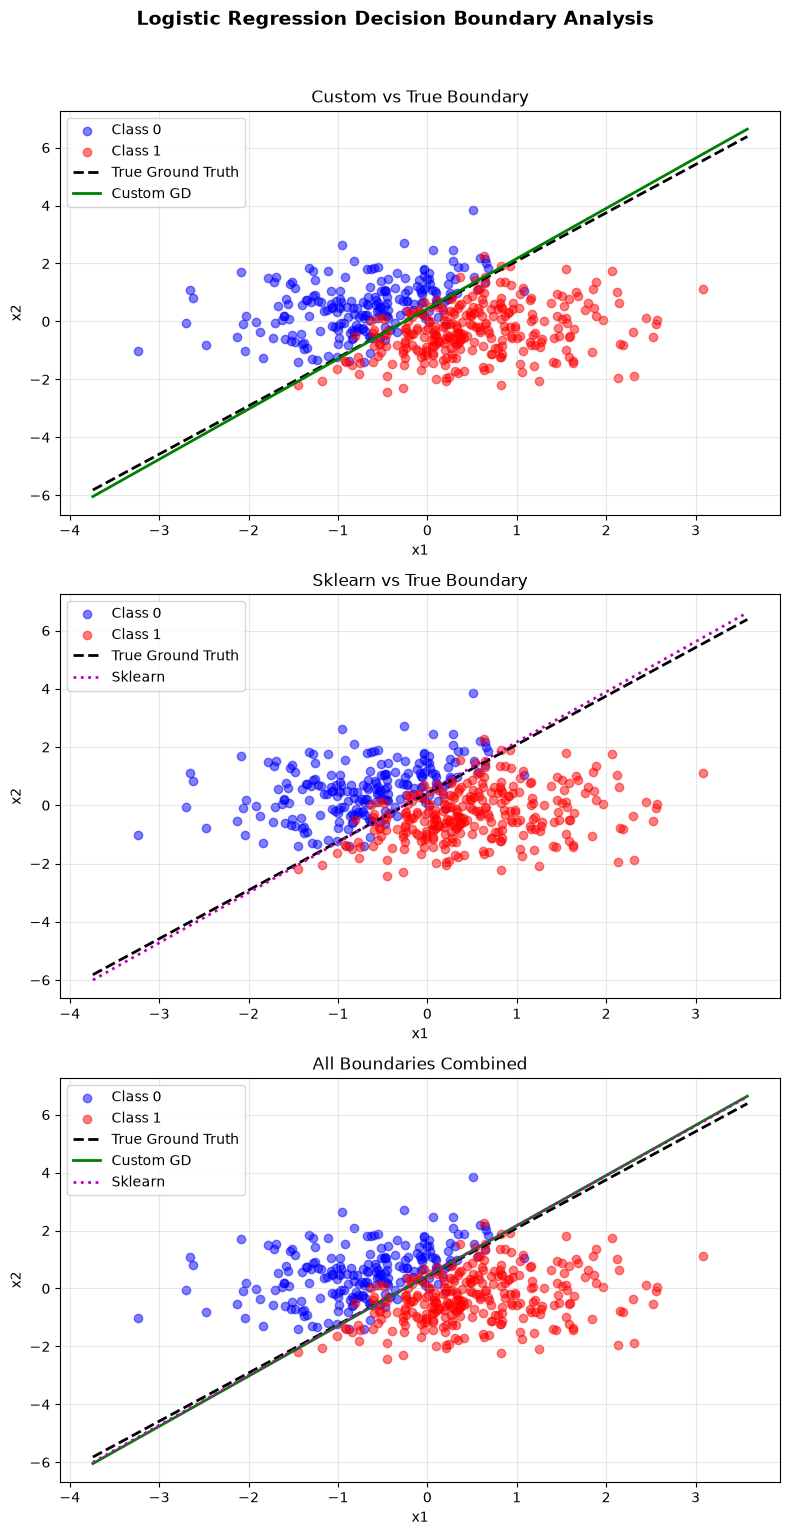

In [18]:
# Create a 3-row, 1-column plot layout
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

# Common logic to plot dataset on a given axis
def plot_base_dataset(ax):
    ax.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='blue', alpha=0.5, label='Class 0')
    ax.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='red', alpha=0.5, label='Class 1')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.grid(True, alpha=0.3)

x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
x2_true = -(true_w[0] * x1_vals + true_b) / true_w[1]
x2_scratch = -(scratch_model.weights[0] * x1_vals + scratch_model.bias) / scratch_model.weights[1]
x2_sk = -(sk_model.coef_[0][0] * x1_vals + sk_model.intercept_[0]) / sk_model.coef_[0][1]

# ----------------- Plot 1: Custom vs True -----------------
plot_base_dataset(axes[0])
axes[0].plot(x1_vals, x2_true, 'k--', linewidth=2, label='True Ground Truth')
axes[0].plot(x1_vals, x2_scratch, 'g-', linewidth=2, label='Custom GD')
axes[0].set_title('Custom vs True Boundary')
axes[0].legend(loc='upper left')

# ----------------- Plot 2: Sklearn vs True -----------------
plot_base_dataset(axes[1])
axes[1].plot(x1_vals, x2_true, 'k--', linewidth=2, label='True Ground Truth')
axes[1].plot(x1_vals, x2_sk, 'm:', linewidth=2, label='Sklearn')
axes[1].set_title('Sklearn vs True Boundary')
axes[1].legend(loc='upper left')

# ----------------- Plot 3: All Three Combined -----------------
plot_base_dataset(axes[2])
axes[2].plot(x1_vals, x2_true, 'k--', linewidth=2, label='True Ground Truth')
axes[2].plot(x1_vals, x2_scratch, 'g-', linewidth=2, label='Custom GD')
axes[2].plot(x1_vals, x2_sk, 'm:', linewidth=2, label='Sklearn')
axes[2].set_title('All Boundaries Combined')
axes[2].legend(loc='upper left')

plt.suptitle('Logistic Regression Decision Boundary Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


# Preventing Weight Explosion — Regularization vs. Data Overlap

In the previous section, we observed that when data is **perfectly linearly separable**, the model weights explode toward infinity because driving logits $z \to \pm\infty$ minimizes the Log Loss toward zero.

Here, we systematically evaluate two distinct approaches to keep learned weights bounded and close to the ground-truth parameters:

1. **Approach 1: L2 Regularization (Mathematical Constraint)** — Adding an explicit weight decay penalty ($\frac{\lambda}{2m}\|\mathbf{w}\|^2$) to constrain weight magnitude during optimization, even on separable data.
2. **Approach 2: Data Overlap / Noise (Realistic Distribution)** — Introducing realistic Gaussian noise into feature boundaries so classes naturally overlap, capping confidence and stopping weight explosion naturally.

## Method 1: L2 Regularization (Ridge Penalty)

To prevent weights from approaching $\pm\infty$ on linearly separable data, we add an **L2 Regularization penalty** ($\frac{\lambda}{2m} \|\mathbf{w}\|^2$) to the loss function.

### 1. Regularized Loss Function
$$J(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right] + \frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2$$

Where $\lambda \ge 0$ is the regularization strength parameter. Note that the bias $b$ is **not** penalized.

### 2. Regularized Gradient Update
The gradient with respect to feature weights includes an extra decay term:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} \mathbf{X}^T (\mathbf{\hat{Y}} - \mathbf{Y}) + \frac{\lambda}{m} \mathbf{w}$$

During Gradient Descent, weights are updated as:
$$\mathbf{w} := \mathbf{w} - \alpha \left( \frac{1}{m} \mathbf{X}^T (\mathbf{\hat{Y}} - \mathbf{Y}) + \frac{\lambda}{m} \mathbf{w} \right) = \mathbf{w}\left(1 - \frac{\alpha \lambda}{m}\right) - \frac{\alpha}{m} \mathbf{X}^T (\mathbf{\hat{Y}} - \mathbf{Y})$$

This decay term continuously pulls the weights toward zero, keeping them bounded.

In [8]:
# Custom Logistic Regression Class with L2 Regularization

class MyLogisticRegressionL2:
    def __init__(self, learning_rate=0.1, epochs=2000, l2_lambda=0.1):
        self.lr = learning_rate
        self.epochs = epochs
        self.l2_lambda = l2_lambda
        self.weights = None
        self.bias = None

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias = 0.0

        for epoch in range(self.epochs):
            # Forward pass
            linear_model = np.dot(X, self.weights) + self.bias
            y_pred_prob = self._sigmoid(linear_model)

            # Gradients with L2 Penalty on weights (bias remains unpenalized)
            dw = (1 / m) * np.dot(X.T, (y_pred_prob - y)) + (self.l2_lambda / m) * self.weights
            db = (1 / m) * np.sum(y_pred_prob - y)

            # Parameter updates
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        return self._sigmoid(np.dot(X, self.weights) + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [9]:
np.random.seed(42)

# Ground Truth Parameters
true_w = np.array([2.0, -1.2])
true_b = 0.5

# Generate Linearly Separable Features & Labels
X_sep = np.random.randn(300, 2)
z_sep = np.dot(X_sep, true_w) + true_b
y_sep = (1.0 / (1.0 + np.exp(-z_sep)) >= 0.5).astype(int)

# 1. Custom GD with L2 Regularization (lambda = 0.5)
scratch_l2 = MyLogisticRegressionL2(learning_rate=0.1, epochs=2000, l2_lambda=0.5)
scratch_l2.fit(X_sep, y_sep)

# 2. Sklearn with L2 Regularization (C = 1 / lambda = 2.0)
# Note: Sklearn uses C = 1 / lambda, so C = 2.0 corresponds to l2_lambda = 0.5
sk_l2 = LogisticRegression(C=2.0, solver='lbfgs')
sk_l2.fit(X_sep, y_sep);

# Display Results
df_reg = pd.DataFrame({
    "Parameter": ["w1 (x1)", "w2 (x2)", "Bias (b)"],
    "Ground Truth": [true_w[0], true_w[1], true_b],
    "Custom GD (L2 Reg)": [scratch_l2.weights[0], scratch_l2.weights[1], scratch_l2.bias],
    "Scikit-Learn (L2 Reg)": [sk_l2.coef_[0][0], sk_l2.coef_[0][1], sk_l2.intercept_[0]]
})

print("=" * 65)
print(" METHOD 1: L2 REGULARIZATION ON LINEARLY SEPARABLE DATA")
print("=" * 65)
print(df_reg.to_string(index=False))

 METHOD 1: L2 REGULARIZATION ON LINEARLY SEPARABLE DATA
Parameter  Ground Truth  Custom GD (L2 Reg)  Scikit-Learn (L2 Reg)
  w1 (x1)           2.0            5.018440               6.053930
  w2 (x2)          -1.2           -3.147212              -3.747665
 Bias (b)           0.5            1.168795               1.434100


## Method 2: Realistic Data Overlap (Noise)

In real-world datasets, classes are rarely perfectly separable. By introducing a small amount of **Gaussian noise** into the linear combination $z$, we simulate natural boundary overlap:

$$z_{\text{noisy}} = \mathbf{w}^T \mathbf{x} + b + \epsilon, \quad \text{where } \epsilon \sim \mathcal{N}(0, \sigma^2)$$

Because Class 0 and Class 1 points now overlap slightly near the decision boundary, $P(y=1)$ can never be driven to absolute $1.0$ or $0.0$ everywhere. This bounds the Log Loss gradient and stops weights from exploding even without regularization.

In [10]:
np.random.seed(42)

# Generate Overlapping Features & Labels using Gaussian noise
X_overlap = np.random.randn(500, 2)
z_overlap = np.dot(X_overlap, true_w) + true_b
noise = np.random.normal(0, 0.5, size=X_overlap.shape[0])  # Noise term
probs_noisy = 1.0 / (1.0 + np.exp(-(z_overlap + noise)))
y_overlap = (probs_noisy >= 0.5).astype(int)

# 1. Custom GD WITHOUT Regularization (l2_lambda = 0.0)
scratch_noisy = MyLogisticRegressionL2(learning_rate=0.1, epochs=2000, l2_lambda=0.0)
scratch_noisy.fit(X_overlap, y_overlap)

# 2. Sklearn WITHOUT Regularization (penalty=None)
sk_noisy = LogisticRegression(penalty=None, solver='lbfgs')
sk_noisy.fit(X_overlap, y_overlap);

# Display Results
df_noise = pd.DataFrame({
    "Parameter": ["w1 (x1)", "w2 (x2)", "Bias (b)"],
    "Ground Truth": [true_w[0], true_w[1], true_b],
    "Custom GD (Noisy Data)": [scratch_noisy.weights[0], scratch_noisy.weights[1], scratch_noisy.bias],
    "Scikit-Learn (Noisy Data)": [sk_noisy.coef_[0][0], sk_noisy.coef_[0][1], sk_noisy.intercept_[0]]
})

print("=" * 65)
print(" METHOD 2: DATA OVERLAP (NOISE) WITHOUT REGULARIZATION")
print("=" * 65)
print(df_noise.to_string(index=False))

 METHOD 2: DATA OVERLAP (NOISE) WITHOUT REGULARIZATION
Parameter  Ground Truth  Custom GD (Noisy Data)  Scikit-Learn (Noisy Data)
  w1 (x1)           2.0                4.834397                   6.264925
  w2 (x2)          -1.2               -2.790327                  -3.554661
 Bias (b)           0.5                1.219662                   1.590108


*Both techniques successfully recover finite weights close to the true parameter values $w_1 = 2.0, w_2 = -1.2, b = 0.5$.*

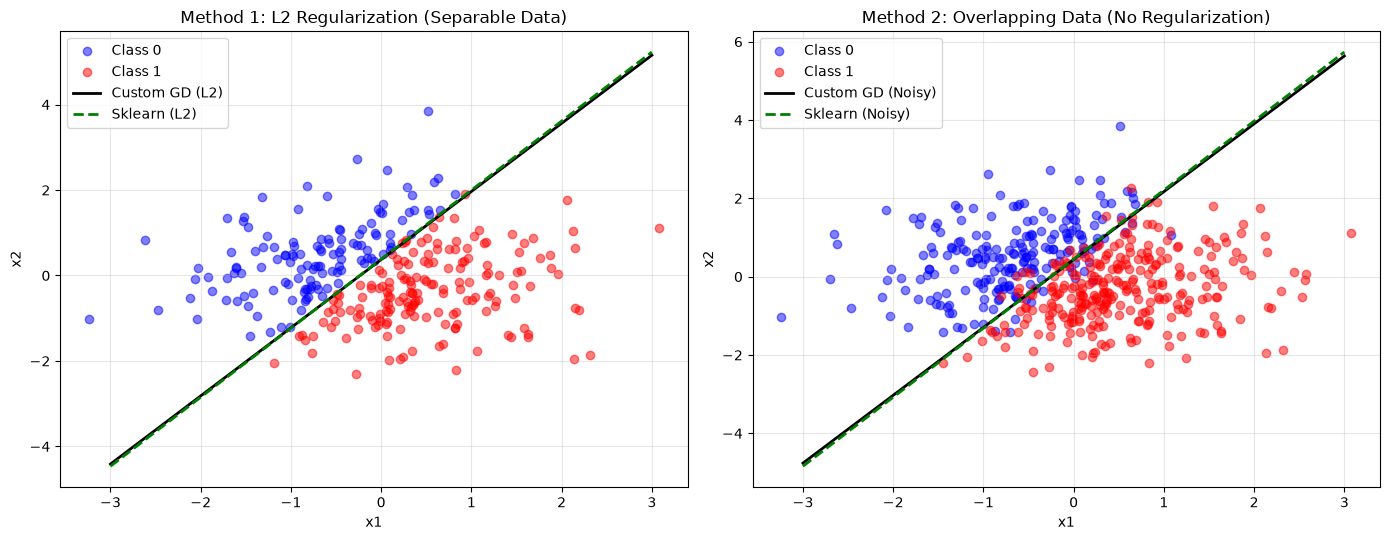

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x1_range = np.linspace(-3, 3, 100)

# -------------------------------------------------------------
# Subplot 1: Regularization on Separable Data
# -------------------------------------------------------------
axes[0].scatter(X_sep[y_sep == 0][:, 0], X_sep[y_sep == 0][:, 1], color='blue', alpha=0.5, label='Class 0')
axes[0].scatter(X_sep[y_sep == 1][:, 0], X_sep[y_sep == 1][:, 1], color='red', alpha=0.5, label='Class 1')

# Custom GD L2 line
line_scratch_l2 = -(scratch_l2.weights[0] * x1_range + scratch_l2.bias) / scratch_l2.weights[1]
axes[0].plot(x1_range, line_scratch_l2, 'k-', linewidth=2, label='Custom GD (L2)')

# Sklearn L2 line
line_sk_l2 = -(sk_l2.coef_[0][0] * x1_range + sk_l2.intercept_[0]) / sk_l2.coef_[0][1]
axes[0].plot(x1_range, line_sk_l2, 'g--', linewidth=2, label='Sklearn (L2)')

axes[0].set_title("Method 1: L2 Regularization (Separable Data)")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# -------------------------------------------------------------
# Subplot 2: Overlapping Data (No Regularization)
# -------------------------------------------------------------
axes[1].scatter(X_overlap[y_overlap == 0][:, 0], X_overlap[y_overlap == 0][:, 1], color='blue', alpha=0.5, label='Class 0')
axes[1].scatter(X_overlap[y_overlap == 1][:, 0], X_overlap[y_overlap == 1][:, 1], color='red', alpha=0.5, label='Class 1')

# Custom GD Noisy line
line_scratch_noisy = -(scratch_noisy.weights[0] * x1_range + scratch_noisy.bias) / scratch_noisy.weights[1]
axes[1].plot(x1_range, line_scratch_noisy, 'k-', linewidth=2, label='Custom GD (Noisy)')

# Sklearn Noisy line
line_sk_noisy = -(sk_noisy.coef_[0][0] * x1_range + sk_noisy.intercept_[0]) / sk_noisy.coef_[0][1]
axes[1].plot(x1_range, line_sk_noisy, 'g--', linewidth=2, label='Sklearn (Noisy)')

axes[1].set_title("Method 2: Overlapping Data (No Regularization)")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()